*Portfolio copy: the Google Drive folder IDs in the data-download cell were replaced with the placeholders `YOUR_IMAGES_FOLDER_ID` and `YOUR_LABELS_FOLDER_ID`; fill them in to run that cell.*

# License Plate Detection & Automatic Blurring with YOLOv8
*Privacy-preserving computer vision for traffic and surveillance imagery*

## 1. Business problem and context

Cameras used for traffic monitoring, parking management, insurance claims and data collection capture vehicles all day, and every frame can expose a **license plate**. Under privacy regulations such as GDPR and CCPA a plate is personally identifiable information (PII), so organisations must anonymise images and video *before* they are stored in the cloud, shared, used to train AI models, or processed by third parties. Doing this by hand does not scale.

**Objective.** Build an automated system that detects license plates with **YOLOv8** and blurs them in images and video streams in near real time, so privacy is protected while the rest of the scene stays useful for analysis.

**The two kinds of error are not equal.** A *missed* plate is a privacy leak (high cost). A *false positive* is just an extra blurred patch (low cost). The system is therefore tuned for **recall first**, and I report recall against false positives rather than only mAP.

**Success criteria**

| Criterion | How it is measured here |
|---|---|
| Detection quality | precision, recall, mAP@50, mAP@50-95 on validation and test |
| Privacy coverage | recall at the chosen confidence threshold, split by plate size |
| Blur effectiveness | can an OCR engine still read the plate after blurring? |
| Speed | milliseconds per frame and frames per second on the Colab device used (stated in the output) |

**Where each business question is answered**

| Question | Section |
|---|---|
| Q1 Convert YOLO coordinates to pixels | 4 |
| Q2 Draw boxes on raw images, and why it matters | 5 |
| Q3 Annotation quality vs. blurring accuracy | 9 (with evidence from 3, 5, 6, 7) |
| Q4 Preprocessing without losing plate detail | 8 |
| Q5 Why YOLOv8, not a two-stage detector | 8 |
| Q6 Which YOLOv8 variant and why | 8 |
| Q7 How plate characteristics drove the model scale | 8 |
| Q8 Blurring only inside the detected box | 10 |

**Data.** Source: a shared Google Drive folder with `images/` and `labels/` (YOLO format, one class: license plate). The full train split has 25,625 images (25,672 label files); val has 1,073 images and test has 386. Reading about 54,000 small files from Drive in Colab was far too slow, so training used a **subset: 11,983 train images** (with their labels), fetched through the Drive API, plus the complete val and test splits. After cleaning (section 7) the working splits are 11,940 / 1,043 / 386. The subset is stored as a zip in Google Drive, and this notebook starts from it.

**How to run.** Colab, ideally with a **T4 GPU** (it also runs on CPU, only slower). The trained weights are stored in Drive (`yolo_runs/lp_v8s`), so by default the notebook loads them instead of retraining; set `RETRAIN = True` in section 8 to train again (about 1.4 hours).

## 2. Setup and reproducibility

In [1]:
!pip -q install ultralytics
import os, re, time, random, shutil, subprocess, glob, warnings
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt
from collections import Counter
from PIL import Image
from IPython.display import display
from google.colab import drive
import torch, ultralytics

warnings.filterwarnings("ignore")
random.seed(42); np.random.seed(42)

drive.mount("/content/drive")
DRIVE  = "/content/drive/MyDrive"
ROOT   = "/content/dataset"                    # working copy: images/, labels/, data.yaml
SPLITS = ["train", "val", "test"]
RUN    = f"{DRIVE}/yolo_runs/lp_v8s"           # training run saved in Drive

print("ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| opencv", cv2.__version__)
DEVICE = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print("Device:", DEVICE, "" if DEVICE != "CPU" else "(no GPU: everything still runs, only slower, and speed figures will be CPU figures)")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Mounted at /content/drive
ultralytics 8.4.208 | torch 2.14.1+cu130 | opencv 4.14.0
Device: Tesla T4 


In [2]:
# Restore the dataset subset (created earlier and stored in Drive) into a clean working folder.
shutil.rmtree(ROOT, ignore_errors=True); shutil.rmtree("/content/removed", ignore_errors=True)
subprocess.run(["unzip", "-q", f"{DRIVE}/lp_dataset.zip", "-d", "/content"], check=True)
for k in ["images", "labels"]:
    print(k, {s: len(os.listdir(f"{ROOT}/{k}/{s}")) for s in SPLITS})

images {'train': 11983, 'val': 1073, 'test': 386}
labels {'train': 11945, 'val': 1073, 'test': 386}


## 3. Data audit

Before any modelling I check the dataset itself: label format, coordinate validity, image sizes, missing labels, and the size and shape of the plates. Every label line should be `class cx cy w h` with values normalised to 0-1.

In [3]:
ROWS, COL_COUNTS, PROBLEMS = [], Counter(), []

for s in SPLITS:
    for img in os.listdir(f"{ROOT}/images/{s}"):
        stem = os.path.splitext(img)[0]
        lp = f"{ROOT}/labels/{s}/{stem}.txt"
        with Image.open(f"{ROOT}/images/{s}/{img}") as im:
            W, H = im.size
        if not os.path.exists(lp):
            PROBLEMS.append((s, img, "no label file")); continue
        lines = [l.split() for l in open(lp).read().strip().splitlines() if l.strip()]
        if not lines:
            PROBLEMS.append((s, img, "empty label file")); continue
        for p in lines:
            COL_COUNTS[len(p)] += 1
            if len(p) < 5:
                PROBLEMS.append((s, img, "malformed line")); continue
            cls, (cx, cy, w, h) = int(float(p[0])), map(float, p[1:5])
            ROWS.append(dict(split=s, img=img, W=W, H=H, cls=cls, cx=cx, cy=cy, w=w, h=h))

df = pd.DataFrame(ROWS)
df["w_px"], df["h_px"] = df.w * df.W, df.h * df.H
df["area_pct"] = df.w * df.h * 100
df["aspect"] = df.w_px / df.h_px

norm = df[["cx", "cy", "w", "h"]]
print("labelled images:", df.groupby(["split", "img"]).ngroups, "| plates:", len(df))
print("columns per label line:", dict(COL_COUNTS), "| class ids:", dict(df.cls.value_counts()))
print("values outside [0,1]:", int(((norm < 0) | (norm > 1)).any(axis=1).sum()), "| zero-size boxes:", int(((df.w <= 0) | (df.h <= 0)).sum()))
print("most common image sizes (W, H):", Counter(zip(df.drop_duplicates(["split", "img"]).W, df.drop_duplicates(["split", "img"]).H)).most_common(4))
print("images without a usable label:", dict(Counter((s, r) for s, _, r in PROBLEMS)))
print("\nplates per image:\n", df.groupby(["split", "img"]).size().describe().round(2).to_string())
print("\nplate size in pixels / share of image:\n", df[["w_px", "h_px", "area_pct", "aspect"]].describe().round(2).to_string())

labelled images: 13399 | plates: 14935
columns per label line: {5: 14935} | class ids: {0: np.int64(14935)}
values outside [0,1]: 0 | zero-size boxes: 0
most common image sizes (W, H): [((416, 416), 10589), ((1024, 768), 1146), ((1024, 683), 328), ((768, 1024), 92)]
images without a usable label: {('train', 'no label file'): 38, ('train', 'empty label file'): 5}

plates per image:
 count    13399.00
mean         1.11
std          0.56
min          1.00
25%          1.00
50%          1.00
75%          1.00
max         26.00

plate size in pixels / share of image:
            w_px      h_px  area_pct    aspect
count  14935.00  14935.00  14935.00  14935.00
mean      86.80     67.07      3.26      1.59
std       89.43     54.56      5.52      0.94
min        5.00      2.00      0.00      0.17
25%       45.50     30.00      0.55      0.80
50%       78.00     53.85      2.11      1.29
75%       94.72    100.00      4.69      2.15
max     1023.36    767.36     99.66     14.33


**What the audit shows**

- Labels are clean in format: every line has exactly five columns, there is a single class, and no coordinate falls outside 0-1 or has zero size.
- Most images are 416x416 (about 10,600 of 13,400 labelled images); the rest are mostly about 1,024 px wide, so the dataset mixes resolutions and sources.
- 43 train images have no label file or an empty one (0.4%). Section 6 shows that most of the ones shown there contain a clearly visible plate, which makes them annotation defects.
- Plates are **small**: the median is about 78x54 px and 2% of the image area, and a quarter of plates are narrower than 45 px.

## 4. Q1 - From normalised YOLO coordinates to pixel coordinates for OpenCV

A YOLO label stores a box *relative to the image*: `cx, cy` is the box centre and `w, h` its size, all divided by the image width `W` and height `H`. OpenCV's `cv2.rectangle` needs **integer pixel corners** `(x1, y1)` (top-left) and `(x2, y2)` (bottom-right), with the origin at the top-left and `y` growing downwards.

$$x_1=(c_x-\tfrac{w}{2})\,W,\quad y_1=(c_y-\tfrac{h}{2})\,H,\quad x_2=(c_x+\tfrac{w}{2})\,W,\quad y_2=(c_y+\tfrac{h}{2})\,H$$

Three details matter: (1) multiply by the *original* image size, not the resized one; (2) round to integers; (3) clamp to `[0, W-1] x [0, H-1]` so boxes touching the border never index outside the image.

In [4]:
def yolo_to_pixel(cx, cy, w, h, img_w, img_h):
    """Normalised YOLO (cx, cy, w, h) -> integer pixel corners (x1, y1, x2, y2), clamped to the image."""
    x1 = int(round((cx - w / 2) * img_w)); y1 = int(round((cy - h / 2) * img_h))
    x2 = int(round((cx + w / 2) * img_w)); y2 = int(round((cy + h / 2) * img_h))
    return max(0, x1), max(0, y1), min(img_w - 1, x2), min(img_h - 1, y2)

def pixel_to_yolo(x1, y1, x2, y2, img_w, img_h):
    """Inverse transform, used here only to test the conversion."""
    return (x1 + x2) / 2 / img_w, (y1 + y2) / 2 / img_h, (x2 - x1) / img_w, (y2 - y1) / img_h

# Unit tests: centred box, both border clamps, a non-square image
CASES = [((0.5, 0.5, 0.2, 0.1, 1000, 500), (400, 225, 600, 275)),
         ((0.05, 0.5, 0.2, 0.2, 100, 100), (0, 40, 15, 60)),
         ((0.95, 0.5, 0.2, 0.2, 100, 100), (85, 40, 99, 60)),
         ((0.25, 0.75, 0.1, 0.2, 640, 480), (128, 312, 192, 408))]
for args, expected in CASES:
    got = yolo_to_pixel(*args)
    assert got == expected, (args, got, expected)

# Round trip on random boxes that lie inside the image: error must stay below one pixel
rng = np.random.default_rng(0)
for _ in range(1000):
    W_, H_ = int(rng.integers(200, 1500)), int(rng.integers(200, 1500))
    w_, h_ = rng.uniform(0.05, 0.4, 2); cx_, cy_ = rng.uniform(w_ / 2 + .01, 1 - w_ / 2 - .01), rng.uniform(h_ / 2 + .01, 1 - h_ / 2 - .01)
    back = pixel_to_yolo(*yolo_to_pixel(cx_, cy_, w_, h_, W_, H_), W_, H_)
    assert abs(back[0] - cx_) * W_ <= 1 and abs(back[1] - cy_) * H_ <= 1 and abs(back[2] - w_) * W_ <= 1.5 and abs(back[3] - h_) * H_ <= 1.5
print("Q1: all unit tests and the 1,000-box round-trip test passed")

# One real example
r = df.iloc[0]
print(f"{r.img}: label (cx={r.cx:.3f}, cy={r.cy:.3f}, w={r.w:.3f}, h={r.h:.3f}) on a {r.W}x{r.H} image ->",
      "pixel box", yolo_to_pixel(r.cx, r.cy, r.w, r.h, r.W, r.H))

Q1: all unit tests and the 1,000-box round-trip test passed
CarLongPlateGen1856_jpg.rf.0284e407b573450f914943562056cebe.jpg: label (cx=0.460, cy=0.364, w=0.210, h=0.089) on a 416x416 image -> pixel box (148, 133, 235, 170)


## 5. Q2 - Overlaying ground-truth boxes on raw images

The function below reads an image, converts every label with `yolo_to_pixel`, and draws the rectangles. The grids show random train and test images with their ground truth.

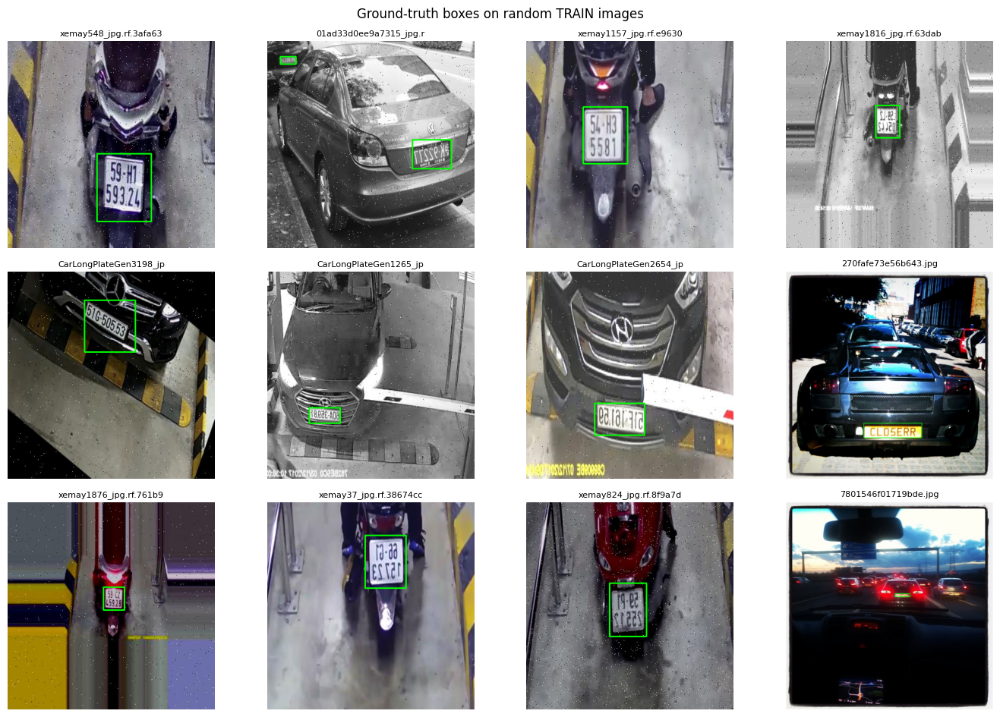

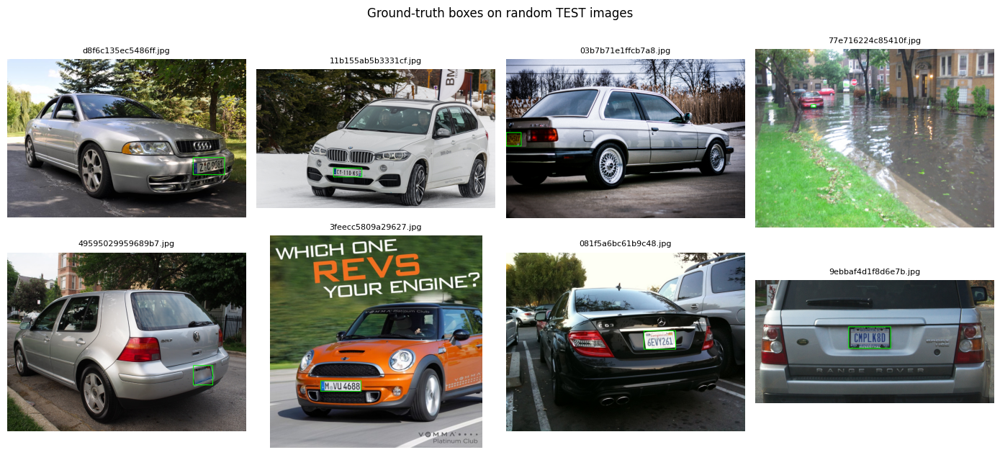

In [5]:
def read_gt(root, split, f, W, H):
    """Ground-truth boxes of one image as float pixel corners, shape (n, 4)."""
    out = []
    lp = f"{root}/labels/{split}/{os.path.splitext(f)[0]}.txt"
    if os.path.exists(lp):
        for l in open(lp).read().strip().splitlines():
            p = l.split()
            if len(p) >= 5:
                cx, cy, w, h = map(float, p[1:5])
                out.append([(cx - w / 2) * W, (cy - h / 2) * H, (cx + w / 2) * W, (cy + h / 2) * H])
    return np.array(out).reshape(-1, 4)

def draw_boxes(img_path, label_path, color=(0, 255, 0), thickness=2):
    """Overlay the ground-truth YOLO boxes on a raw image; returns an RGB array."""
    img = cv2.imread(img_path); H, W = img.shape[:2]
    if os.path.exists(label_path):
        for l in open(label_path).read().strip().splitlines():
            p = l.split()
            if len(p) < 5: continue
            cx, cy, w, h = map(float, p[1:5])
            x1, y1, x2, y2 = yolo_to_pixel(cx, cy, w, h, W, H)
            cv2.rectangle(img, (x1, y1), (x2, y2), color, thickness)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def show_files(items, title, cols=4, root=ROOT):
    """items = [(split, filename), ...] drawn with their ground truth."""
    if not items: print("none:", title); return
    r = (len(items) + cols - 1) // cols
    fig, axes = plt.subplots(r, cols, figsize=(14, 3.2 * r)); axes = np.atleast_1d(axes).ravel()
    for a in axes: a.axis("off")
    for a, (s, f) in zip(axes, items):
        a.imshow(draw_boxes(f"{root}/images/{s}/{f}", f"{root}/labels/{s}/{os.path.splitext(f)[0]}.txt"))
        a.set_title(f[:22], fontsize=8)
    plt.suptitle(title); plt.tight_layout(); plt.show()

def sample_items(split, n, seed=0):
    names = sorted(os.listdir(f"{ROOT}/images/{split}"))
    return [(split, f) for f in np.random.default_rng(seed).choice(names, n, replace=False)]

show_files(sample_items("train", 12), "Ground-truth boxes on random TRAIN images")
show_files(sample_items("test", 8), "Ground-truth boxes on random TEST images")

**Why this check is critical before training.** A detector can only be as good as its labels, and the most common label bugs are silent: they do not crash anything, they just teach the model the wrong thing. Drawing the boxes on raw images catches them in seconds:

- a wrong coordinate convention (corner vs. centre, or `x`/`y` swapped) shifts every box;
- boxes normalised by the wrong image size, or labels that no longer match images that were resized or augmented;
- wrong class ids, missing labels, and boxes that are clearly too loose or too tight.

If these go uncaught, hours of GPU time produce a model that looks fine on loss curves but fails on real data, and in this project a silent miss means an **unblurred plate**. Here the overlays show boxes sitting on the plates, including on noisy, stretched and rotated augmented images, so the conversion and the labels are trustworthy. The same audit also found a few images whose visible plates have no box (section 6).

## 6. Exploratory analysis: plate size, shape, sources and label problems

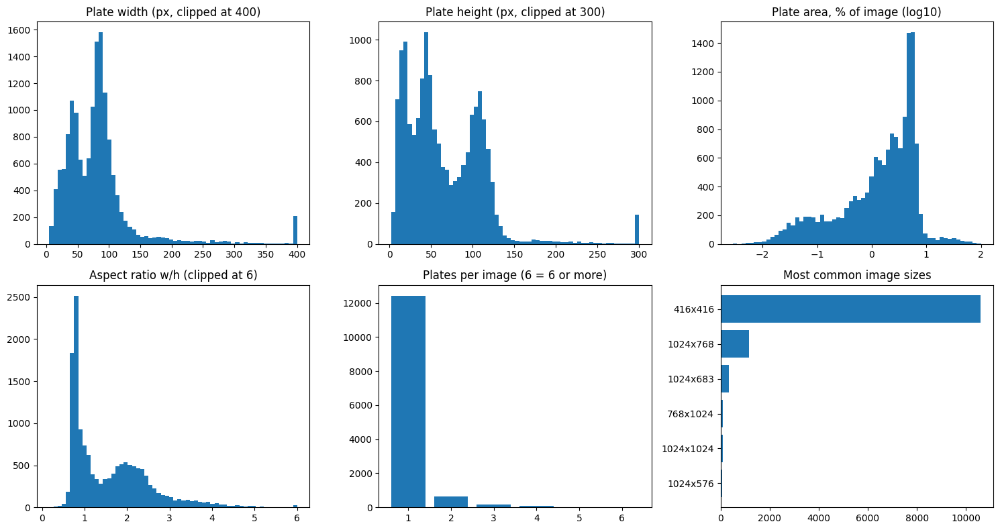

In [6]:
imgs_df = df.drop_duplicates(["split", "img"])
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax[0, 0].hist(df.w_px.clip(upper=400), bins=60); ax[0, 0].set(title="Plate width (px, clipped at 400)")
ax[0, 1].hist(df.h_px.clip(upper=300), bins=60); ax[0, 1].set(title="Plate height (px, clipped at 300)")
ax[0, 2].hist(np.log10(df.area_pct.clip(lower=1e-3)), bins=60); ax[0, 2].set(title="Plate area, % of image (log10)")
ax[1, 0].hist(df.aspect.clip(upper=6), bins=60); ax[1, 0].set(title="Aspect ratio w/h (clipped at 6)")
bpi = df.groupby(["split", "img"]).size().clip(upper=6).value_counts().sort_index()
ax[1, 1].bar(bpi.index, bpi.values); ax[1, 1].set(title="Plates per image (6 = 6 or more)")
sz = Counter(zip(imgs_df.W, imgs_df.H)).most_common(6)[::-1]
ax[1, 2].barh([f"{w}x{h}" for (w, h), _ in sz], [c for _, c in sz]); ax[1, 2].set(title="Most common image sizes")
plt.tight_layout(); plt.show()

363 suspicious boxes of 14935 (2.43%); by split: {'test': np.int64(14), 'train': np.int64(217), 'val': np.int64(132)}


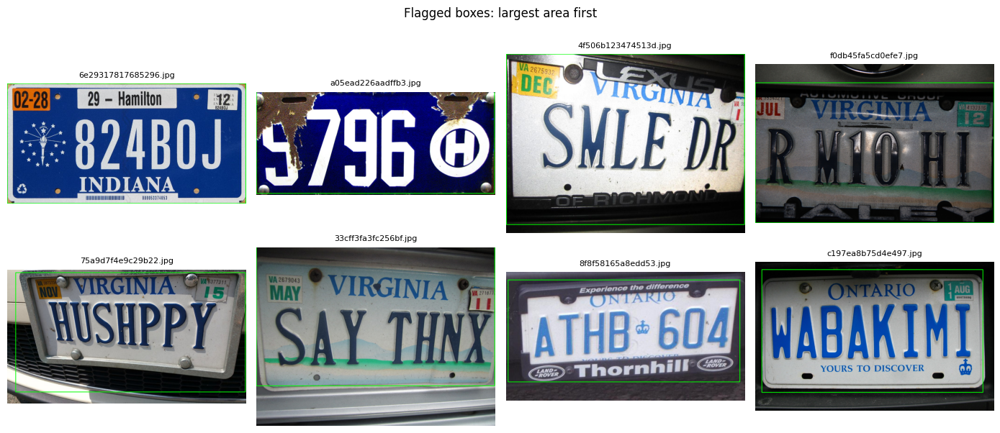

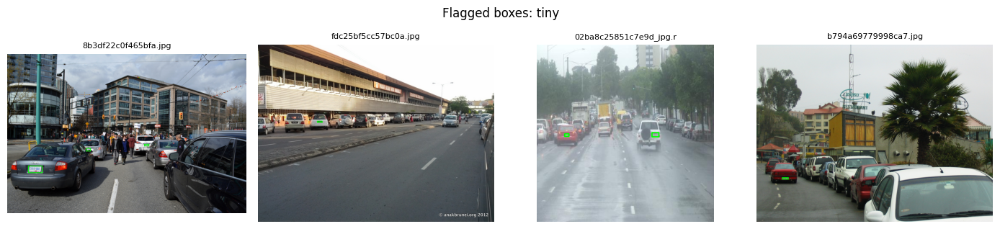

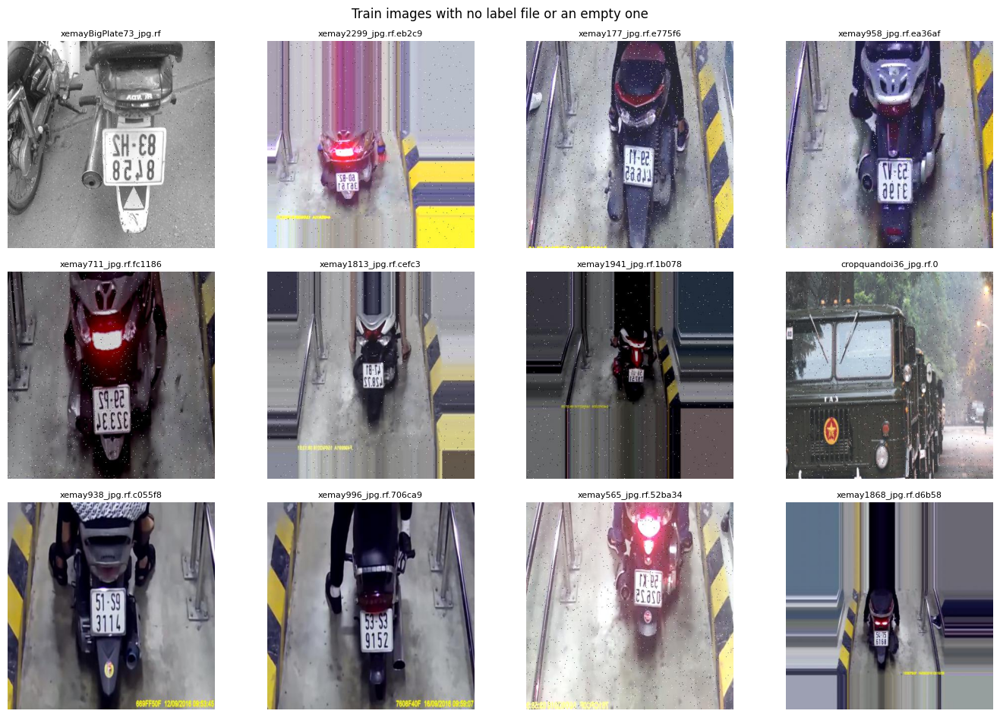

,images,unique_sources,copies_per_source
split,,,
test,386,386,1.00
train,11940,7385,1.62
val,1073,1073,1.00


source photos shared -> train&val: 30 | train&test: 0 | val&test: 0


,plates,median_aspect,median_w_px
group,,,
xemay,5449,0.78,76.00
CarLongPlateGen,2912,2.02,90.00
CarLongPlate,756,2.21,92.50
xemayBigPlate,579,1.06,112.50
Cars,248,1.89,73.50
a,174,2.11,53.76


In [7]:
# 1) Suspicious boxes (very large, tiny, or extreme aspect ratio) - then LOOK at them
sus = df[(df.area_pct > 50) | (df.w_px < 10) | (df.h_px < 8) | (df.aspect > 8) | (df.aspect < 0.3)]
print(f"{len(sus)} suspicious boxes of {len(df)} ({len(sus) / len(df):.2%}); by split:", dict(sus.groupby('split').size()))
big = sus.sort_values("area_pct", ascending=False).drop_duplicates(["split", "img"])
show_files(list(zip(big.split, big.img))[:8], "Flagged boxes: largest area first")
tiny = sus[(sus.w_px < 10) | (sus.h_px < 8)].drop_duplicates(["split", "img"])
show_files(list(zip(tiny.split, tiny.img))[:4], "Flagged boxes: tiny")

# 2) Images with no / empty label file
show_files([(s, f) for s, f, r in PROBLEMS][:12], "Train images with no label file or an empty one")

# 3) Source photos shared between splits (augmented copies) and vehicle groups
def base(f):
    m = re.match(r"^(.*?)_(?:jpg|jpeg|png)\.rf\.", f, re.I)
    return m.group(1) if m else os.path.splitext(f)[0]
imgs_df = imgs_df.assign(base=imgs_df.img.map(base), group=imgs_df.img.str.extract(r"^([A-Za-z]+)")[0])
summ = imgs_df.groupby("split").agg(images=("img", "size"), unique_sources=("base", "nunique"))
summ["copies_per_source"] = (summ.images / summ.unique_sources).round(2)
display(summ)
SRC_BASES = {s: set(imgs_df[imgs_df.split == s].base) for s in SPLITS}
print("source photos shared -> train&val:", len(SRC_BASES["train"] & SRC_BASES["val"]),
      "| train&test:", len(SRC_BASES["train"] & SRC_BASES["test"]), "| val&test:", len(SRC_BASES["val"] & SRC_BASES["test"]))

# 4) Plate shape by vehicle group
display(df.assign(group=df.img.str.extract(r"^([A-Za-z]+)")[0]).groupby("group")
        .agg(plates=("aspect", "size"), median_aspect=("aspect", "median"), median_w_px=("w_px", "median")).round(2)
        .sort_values("plates", ascending=False).head(6))

**Insights from the exploration**

1. **Plates are small, and size is the central difficulty.** Median area is about 2% of the image and a quarter of the plates are below 0.55%. Many are only tens of pixels wide.
2. **Plate shape depends on the vehicle.** Motorbike plates (two-line, near-square) have a median aspect ratio of about 0.8-1.1; car plates are about 2.0-2.2. Aspect ratio is bimodal, so any single "typical plate" assumption would be wrong.
3. **There are two image sources.** About 81% of train images are parking-camera frames (filenames starting `xemay` / `CarLongPlate`, mostly 416x416). The rest are web photos (hash filenames, about 1,024 px wide) with plates from several countries, many of them small and distant.
4. **The flagged "suspicious" boxes are mostly valid.** The very large boxes are correct close-ups of plates, and the tiny boxes sit on real distant cars. So the size filter found few true errors.
5. **Real annotation defects exist.** Of the 12 unlabeled train images shown above, 11 contain a clearly readable plate with no box (the 12th, a military truck, shows no plate). Left in training they would teach the model to ignore visible plates, which is a privacy leak.
6. **Train contains augmented copies.** Train has about 1.6 images per source photo (augmentation), whereas val and test have one. **30 val images share a source photo with train**, which would inflate validation scores; test shares none.

## 7. Cleaning and the train/val/test composition

Actions: (a) move the 43 train images with missing or empty labels out of the dataset (they are kept in `/content/removed`, not deleted); (b) move the 30 val images whose source photo also appears in train; (c) write `data.yaml`.

In [8]:
REM = "/content/removed"

def move_out(split, img):
    stem = os.path.splitext(img)[0]
    for k, name in (("images", img), ("labels", stem + ".txt")):
        src = f"{ROOT}/{k}/{split}/{name}"
        if os.path.exists(src):
            os.makedirs(f"{REM}/{k}/{split}", exist_ok=True)
            shutil.move(src, f"{REM}/{k}/{split}/{name}")

for s, f, r in PROBLEMS:
    if r in ("no label file", "empty label file"):
        move_out(s, f)
leak = SRC_BASES["train"] & SRC_BASES["val"]
for f in os.listdir(f"{ROOT}/images/val"):
    if base(f) in leak:
        move_out("val", f)

open(f"{ROOT}/data.yaml", "w").write(
    f"path: {ROOT}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: license_plate\n")

comp = []
for s in SPLITS:
    n = os.listdir(f"{ROOT}/images/{s}")
    assert len(n) == len(os.listdir(f"{ROOT}/labels/{s}")), f"{s}: image/label count mismatch"
    cam = sum(f.startswith(("xemay", "CarLongPlate")) for f in n)
    comp.append(dict(split=s, images=len(n), parking_camera=cam, web_photos=len(n) - cam))
display(pd.DataFrame(comp))

,split,images,parking_camera,web_photos
0,train,11940,9695,2245
1,val,1043,0,1043
2,test,386,0,386


**A finding that shapes how results must be read.** Training is about 81% parking-camera images, but **val and test contain only web photos**. The validation and test scores in section 9 therefore measure the harder web-photo domain only. To check the parking-camera case I build a separate held-out set from images the model never saw (section 9).

## 8. Model choice and training

### Design decisions (Q4, Q5, Q6, Q7)

**Q4 - Preprocessing without losing plate detail**

- *No lossy steps.* Images are read as they are: no re-compression, denoising, grayscale conversion or cropping. Colour is kept because plate colour (white, yellow, blue) is a useful cue.
- *Letterbox resize to 640x640.* YOLOv8 scales the longer side to 640 and pads the rest, so plates keep their true aspect ratio (stretching would distort the 0.8-2.2 shape cue). Pixel values are scaled to 0-1 internally.
- *Resolution chosen from the data.* The median plate is about 78x54 px, a quarter are narrower than about 45 px, and about 11% of validation plates are under 20 px wide. The 416 px parking images are enlarged to 640, while the roughly 1,024 px web photos are shrunk by about 0.6, which makes their small plates smaller still. The recall-by-size table in section 9 confirms that this is the main failure mode.
- *Augmentation.* Mosaic, colour (HSV) jitter, scale and translation, and horizontal flip (Ultralytics defaults, with mosaic switched off for the last 5 epochs). A flip mirrors the text, which is harmless for *detection*, and none of these steps destroys detail.
- *Data hygiene as preprocessing.* Missing-label images and validation leakage were removed (section 7) and a fixed seed was used.

**Q5 - Why YOLOv8 rather than a two-stage detector.** Plate blurring is a high-throughput, deployment-driven task: video streams and edge cameras need low latency per frame, and the object is simple (one class, a rigid rectangle). YOLOv8 is single-stage: one network pass predicts boxes directly (anchor-free, decoupled head) followed by non-maximum suppression, with no separate region-proposal and refinement stage as in Faster R-CNN. That makes it typically much faster and smaller, easy to export to ONNX or TensorRT, and simple to train and maintain. Two-stage detectors can localise slightly better and sometimes cope better with very small objects, but at higher compute and complexity; for blurring I need the plate *covered*, not pixel-perfect boxes (I pad each box by 8%). *Honest note:* I did not train a two-stage baseline, so this is a design argument backed by the latency measured in section 12, not a head-to-head experiment.

**Q6 - Variant: YOLOv8s ("small").** The family trades size for accuracy: n (3.2 M parameters), s (11.1 M), m (25.9 M), l, x. I chose **s** (11.1 M parameters, 28.4 GFLOPs, as printed by Ultralytics during evaluation) because (1) it is fast enough for real time on a T4 and light enough for edge export; (2) it has noticeably more capacity than n for small plates in cluttered scenes, which is where this dataset is hardest; (3) m, l and x would multiply training time on a free T4 (my 25-epoch run already took 1.35 hours) with diminishing returns for a single, simple class. *Limit:* I did not train n or m, so the speed/accuracy balance is argued from model specifications and measured latency, not from a controlled comparison.

**Q7 - How plate characteristics shaped the model scale.**
1. *One visually distinctive class.* A rigid, high-contrast rectangle with text needs little classification capacity, so a small or medium model is enough and l/x would be waste.
2. *Small objects.* The median plate covers 2% of the image and a quarter cover under 0.55%. Detecting them depends on fine, high-resolution features (YOLOv8 predicts at strides 8, 16 and 32, and stride 8 serves small plates). This pushed me to 640 px input, and it means the remaining errors are limited by *resolution*, not model capacity.
3. *Shape varies by vehicle.* Median aspect ratio is about 0.8 for motorbike plates and 2.0-2.2 for car plates. An anchor-free head regresses width and height directly, so no hand-tuned anchor shapes are needed.
4. *Two domains.* Tight parking-camera plates are nearly solved by the small model (section 9), while distant plates in web photos would gain more from a larger input size than from a larger model.

### Training run
Trained once on a Colab T4 (settings below). To keep this notebook quick and reproducible it loads the saved weights; set `RETRAIN = True` to train again.

In [9]:
from ultralytics import YOLO

RETRAIN = False     # True: retrain from scratch (about 1.4 h on a T4).  False: load the weights saved in Drive.
if RETRAIN:
    YOLO("yolov8s.pt").train(data=f"{ROOT}/data.yaml", epochs=25, imgsz=640, batch=32, workers=2,
                             patience=8, close_mosaic=5, seed=42,
                             project=f"{DRIVE}/yolo_runs", name="lp_v8s", exist_ok=True)

BEST = f"{RUN}/weights/best.pt"
assert os.path.exists(BEST), "best.pt not found: check the Drive path or set RETRAIN = True"
model = YOLO(BEST)

import yaml
args_path = f"{RUN}/args.yaml"
if os.path.exists(args_path):
    a = yaml.safe_load(open(args_path))
    keys = ["model", "epochs", "imgsz", "batch", "optimizer", "lr0", "seed", "close_mosaic", "patience", "workers", "mosaic", "fliplr", "hsv_h", "hsv_s", "hsv_v"]
    print("training settings used:", {k: a.get(k) for k in keys})

training settings used: {'model': 'yolov8s.pt', 'epochs': 25, 'imgsz': 640, 'batch': 32, 'optimizer': 'auto', 'lr0': 0.01, 'seed': 42, 'close_mosaic': 5, 'patience': 8, 'workers': 2, 'mosaic': 1.0, 'fliplr': 0.5, 'hsv_h': 0.015, 'hsv_s': 0.7, 'hsv_v': 0.4}


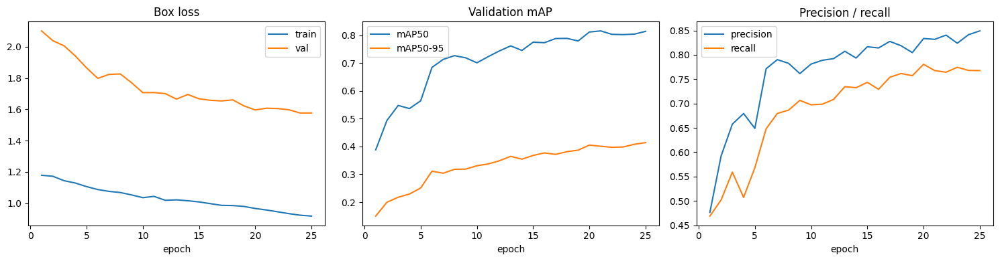

epochs run: 25 | final val mAP50-95 0.414 (still rising slowly: more epochs would help)


In [10]:
# Training curves from the saved log
r = pd.read_csv(f"{RUN}/results.csv"); r.columns = r.columns.str.strip()
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(r.epoch, r["train/box_loss"], label="train"); ax[0].plot(r.epoch, r["val/box_loss"], label="val"); ax[0].set_title("Box loss")
ax[1].plot(r.epoch, r["metrics/mAP50(B)"], label="mAP50"); ax[1].plot(r.epoch, r["metrics/mAP50-95(B)"], label="mAP50-95"); ax[1].set_title("Validation mAP")
ax[2].plot(r.epoch, r["metrics/precision(B)"], label="precision"); ax[2].plot(r.epoch, r["metrics/recall(B)"], label="recall"); ax[2].set_title("Precision / recall")
for a_ in ax: a_.set_xlabel("epoch"); a_.legend()
plt.tight_layout(); plt.show()
print(f"epochs run: {int(r.epoch.max())} | final val mAP50-95 {r['metrics/mAP50-95(B)'].iloc[-1]:.3f} (still rising slowly: more epochs would help)")

**Reading the curves.** Train and validation loss both fall steadily and mAP keeps creeping upward until the last epoch: there is no sign of over-fitting, and the model is, if anything, slightly under-trained. Section 13 lists more training and a larger input size as next steps.

## 9. Evaluation

Three views of performance: (1) standard detection metrics on validation and test; (2) **recall against false positives** across confidence thresholds, which is what matters for privacy; (3) a held-out set for the parking-camera domain, because val and test cover only web photos.

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2986.5±938.7 MB/s, size: 307.6 KB)
val: Scanning /content/dataset/labels/val... 1043 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1043/1043 1.9Kit/s 0.6s
val: New cache created: /content/dataset/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 2.1it/s 15.8s
                   all       1043       1540      0.853      0.771       0.82      0.416
Speed: 1.2ms preprocess, 6.3ms inference, 0.0ms loss, 2.3ms postprocess per image
Results saved to /content/runs/eval_val
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3528.0±701

,P,R,mAP50,mAP50_95
"val (web photos, 1,043 imgs)",0.853,0.771,0.820,0.416
"test (web photos, 386 imgs)",0.914,0.812,0.881,0.640


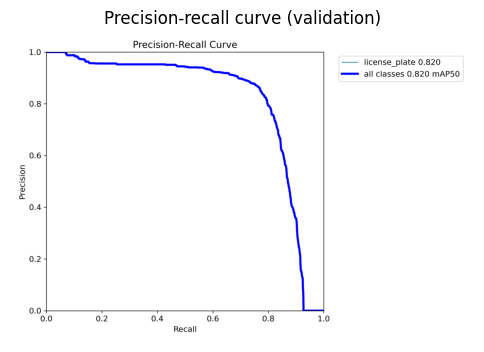

In [11]:
RESULTS = {}
def evaluate(split, yaml_path=f"{ROOT}/data.yaml", plots=False, name=None):
    m = model.val(data=yaml_path, split=split, imgsz=640, batch=32, plots=plots, verbose=False,
                  project="/content/runs", name=name or f"eval_{split}", exist_ok=True)
    return dict(P=m.box.mp, R=m.box.mr, mAP50=m.box.map50, mAP50_95=m.box.map)

RESULTS["val (web photos, 1,043 imgs)"]  = evaluate("val", plots=True)
RESULTS["test (web photos, 386 imgs)"]   = evaluate("test")
display(pd.DataFrame(RESULTS).T.round(3))

pr = glob.glob("/content/runs/eval_val/*PR_curve.png")
if pr:
    plt.figure(figsize=(6, 5)); plt.imshow(plt.imread(pr[0])); plt.axis("off"); plt.title("Precision-recall curve (validation)"); plt.show()

**Reading the table.** On the web-photo validation set the model reaches mAP@50 of about 0.82 and mAP@50-95 of about 0.42; on the test set the figures are higher (about 0.88 and 0.64). Test is smaller (386 images, 512 plates) and easier, so both numbers are reported rather than only the better one. mAP@50-95 is low relative to mAP@50 because it demands very tight boxes; for blurring, covering the plate matters more than exact edges.

In [12]:
def iou_mat(a, b):
    """Pairwise IoU between two sets of (x1, y1, x2, y2) boxes."""
    if len(a) == 0 or len(b) == 0: return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = lambda z: (z[:, 2] - z[:, 0]) * (z[:, 3] - z[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter)

def predict_all(root, split, conf, bs=64):
    """Yield (filename, (H, W), predicted boxes, scores) for every image of a split."""
    files = sorted(os.listdir(f"{root}/images/{split}"))
    for i in range(0, len(files), bs):
        chunk = files[i:i + bs]
        for f, res in zip(chunk, model.predict([f"{root}/images/{split}/{f}" for f in chunk], conf=conf, imgsz=640, verbose=False)):
            yield f, res.orig_shape, res.boxes.xyxy.cpu().numpy(), res.boxes.conf.cpu().numpy()

def recall_vs_conf(root, split, thresholds=(0.05, 0.10, 0.15, 0.25, 0.40, 0.50), iou_thr=0.5):
    """Plate recall (ground-truth plates matched by a prediction with IoU >= iou_thr) and false positives per threshold."""
    tp = {t: 0 for t in thresholds}; fp = dict(tp); n_gt = 0; n_img = 0
    for f, (H, W), pb, pc in predict_all(root, split, min(thresholds)):
        gt = read_gt(root, split, f, W, H); n_gt += len(gt); n_img += 1
        for t in thresholds:
            keep = pb[pc >= t]; M = iou_mat(gt, keep)
            tp[t] += int((M.max(axis=1) >= iou_thr).sum()) if M.size else 0
            fp[t] += len(keep) - (int((M.max(axis=0) >= iou_thr).sum()) if M.size else 0)
    return pd.DataFrame({"conf": thresholds, "recall": [tp[t] / n_gt for t in thresholds],
                         "false_positives": [fp[t] for t in thresholds],
                         "false_pos_per_image": [fp[t] / n_img for t in thresholds]}).round(3)

print("VALIDATION (used to choose the threshold)"); display(recall_vs_conf(ROOT, "val"))
print("TEST (reported)"); display(recall_vs_conf(ROOT, "test"))

VALIDATION (used to choose the threshold)


,conf,recall,false_positives,false_pos_per_image
0,0.05,0.867,898,0.861
1,0.10,0.850,594,0.570
2,0.15,0.838,467,0.448
3,0.25,0.814,320,0.307
4,0.40,0.769,183,0.175
5,0.50,0.701,117,0.112


TEST (reported)


,conf,recall,false_positives,false_pos_per_image
0,0.05,0.908,237,0.614
1,0.10,0.891,150,0.389
2,0.15,0.883,107,0.277
3,0.25,0.842,64,0.166
4,0.40,0.809,28,0.073
5,0.50,0.771,16,0.041


**Choosing the operating point.** Lowering the confidence threshold buys recall at the price of extra blurred patches. I pick **`CONF = 0.10`** on the validation set: going from 0.25 to 0.10 adds about 4 points of recall, whereas going further to 0.05 adds only about 2 more points for many more false blurs. On the test set this threshold finds roughly 89% of plates with about 0.4 false blurs per image. A wrongly blurred patch is cheap and a missed plate is not, so a low threshold is the right trade for a privacy tool.

In [13]:
CONF = 0.10     # operating point chosen from the validation table above
PAD  = 0.08     # each box is enlarged by 8% before blurring

### Held-out parking-camera set

Val and test contain no parking-camera images, so I evaluate that domain on **400 images from the original train split that were never downloaded for training**, keeping only images whose source photo does not appear in anything the model trained on (one image per source photo). *Caveat:* parking cameras are fixed, so backgrounds are similar across different photos; this set is therefore somewhat optimistic, but it is far better than no measurement. The first run builds the set through the Drive API (it asks for a Google sign-in) and stores it in Drive as `lp_heldout.zip`; later runs just unzip it.

In [14]:
HELD = "/content/heldout"
BUILD_HELDOUT = not os.path.exists(f"{DRIVE}/lp_heldout.zip")    # first run: build through the Drive API (Google sign-in); later runs reuse the stored zip

if BUILD_HELDOUT:
    import threading, requests
    from google.colab import auth
    import google.auth
    from google.auth.transport.requests import Request
    from concurrent.futures import ThreadPoolExecutor
    auth.authenticate_user(); creds, _ = google.auth.default()
    lock, tl, API = threading.Lock(), threading.local(), "https://www.googleapis.com/drive/v3/files"
    def token():
        with lock:
            if not creds.valid: creds.refresh(Request())
            return creds.token
    def api_get(url, params=None, stream=False, tries=8):
        if not hasattr(tl, "s"): tl.s = requests.Session()
        for i in range(tries):
            r_ = tl.s.get(url, params=params, stream=stream, timeout=60, headers={"Authorization": f"Bearer {token()}"})
            if r_.status_code == 200: return r_
            if r_.status_code == 401:
                with lock: creds.refresh(Request())
            time.sleep(min(2 ** i, 30))
        r_.raise_for_status()
    def list_children(fid):
        out, page = [], None
        while True:
            p = {"q": f"'{fid}' in parents and trashed=false", "fields": "nextPageToken,files(id,name)", "pageSize": 1000,
                 "supportsAllDrives": "true", "includeItemsFromAllDrives": "true"}
            if page: p["pageToken"] = page
            j = api_get(API, p).json(); out += j["files"]; page = j.get("nextPageToken")
            if not page: return out
    def dl_to(item, dest):
        if os.path.exists(dest) and os.path.getsize(dest) > 0: return
        r_ = api_get(f"{API}/{item['id']}", {"alt": "media", "supportsAllDrives": "true"}, stream=True)
        with open(dest + ".part", "wb") as fh:
            for chunk in r_.iter_content(1 << 16): fh.write(chunk)
        os.replace(dest + ".part", dest)
    IMG_ID, LBL_ID = "YOUR_IMAGES_FOLDER_ID", "YOUR_LABELS_FOLDER_ID"     # Drive folder ids of images/ and labels/
    sub = lambda fid, name: next(f["id"] for f in list_children(fid) if f["name"] == name)
    img_all, lbl_all = list_children(sub(IMG_ID, "train")), list_children(sub(LBL_ID, "train"))
    lbl_by_stem = {os.path.splitext(f["name"])[0]: f for f in lbl_all}
    used = {base(f) for f in os.listdir(f"{ROOT}/images/train")} | {base(f) for f in os.listdir(f"{REM}/images/train")}
    cand = [f for f in img_all if f["name"].startswith(("xemay", "CarLongPlate"))
            and base(f["name"]) not in used and os.path.splitext(f["name"])[0] in lbl_by_stem]
    random.Random(42).shuffle(cand)
    seen, picked = set(), []
    for f in cand:
        if base(f["name"]) not in seen: seen.add(base(f["name"])); picked.append(f)
        if len(picked) == 400: break
    for k in ("images", "labels"): os.makedirs(f"{HELD}/{k}/test", exist_ok=True)
    def dl_pair(img):
        lbl = lbl_by_stem[os.path.splitext(img["name"])[0]]
        dl_to(lbl, f"{HELD}/labels/test/{lbl['name']}"); dl_to(img, f"{HELD}/images/test/{img['name']}")
    with ThreadPoolExecutor(16) as ex: list(ex.map(dl_pair, picked))
    open(f"{HELD}/data.yaml", "w").write(f"path: {HELD}\ntrain: images/test\nval: images/test\ntest: images/test\nnames:\n  0: license_plate\n")
    subprocess.run(["zip", "-rq0", f"{DRIVE}/lp_heldout.zip", "heldout"], cwd="/content", check=True)   # store it for next time
else:
    shutil.rmtree(HELD, ignore_errors=True)
    subprocess.run(["unzip", "-q", f"{DRIVE}/lp_heldout.zip", "-d", "/content"], check=True)

print("held-out images:", len(os.listdir(f"{HELD}/images/test")), "| labels:", len(os.listdir(f"{HELD}/labels/test")))
RESULTS["held-out parking camera (400 imgs)"] = evaluate("test", yaml_path=f"{HELD}/data.yaml", name="eval_heldout")
display(pd.DataFrame(RESULTS).T.round(3))
print("held-out recall vs. confidence:"); display(recall_vs_conf(HELD, "test", thresholds=(0.10, 0.25)))

held-out images: 400 | labels: 400
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 834.1±333.6 MB/s, size: 33.9 KB)
val: Scanning /content/heldout/labels/test... 400 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 400/400 1.8Kit/s 0.2s
val: New cache created: /content/heldout/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 2.2it/s 6.0s
                   all        400        400      0.999          1      0.995      0.674
Speed: 1.2ms preprocess, 8.8ms inference, 0.0ms loss, 1.5ms postprocess per image


,P,R,mAP50,mAP50_95
"val (web photos, 1,043 imgs)",0.853,0.771,0.820,0.416
"test (web photos, 386 imgs)",0.914,0.812,0.881,0.640
held-out parking camera (400 imgs),0.999,1.000,0.995,0.674


held-out recall vs. confidence:


,conf,recall,false_positives,false_pos_per_image
0,0.10,1.0,2,0.005
1,0.25,1.0,0,0.000


**Result.** On unseen parking-camera images the model finds essentially every plate (recall about 1.00, precision about 1.00, mAP@50 about 0.995) with almost no false positives (2 at the 0.10 threshold). So the dominant real-world case is effectively solved, and the weaknesses are concentrated in small, distant plates in web photos. The mAP@50-95 of about 0.67 despite mAP@50 near 0.995 means the plate is found almost every time but box edges differ from the annotator's by a few pixels.

### Where does it miss? Recall by plate size (validation, `CONF = 0.10`)

,plates,recall,missed
plate width,,,
< 20 px,170,0.488,87
20-40 px,426,0.824,75
40-80 px,403,0.931,28
80-160 px,273,0.952,13
> 160 px,268,0.896,28


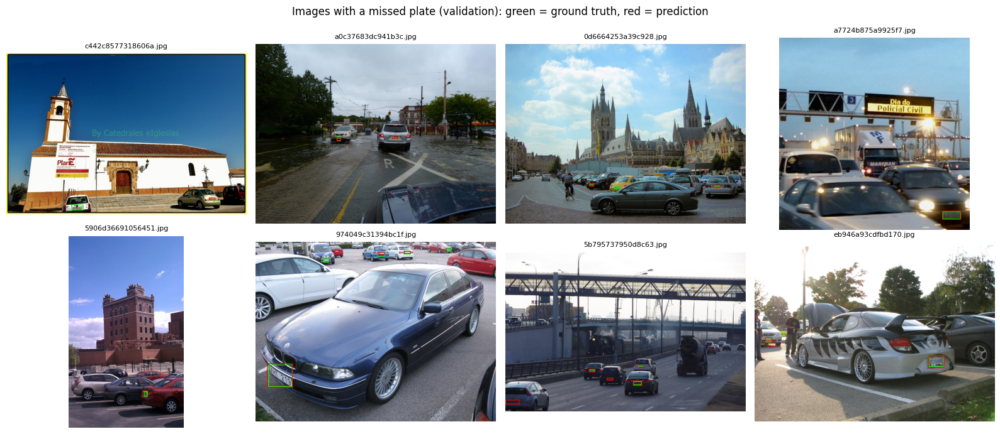

In [15]:
def gt_hits(root, split, conf, iou_thr=0.5):
    rows = []
    for f, (H, W), pb, pc in predict_all(root, split, conf):
        gt = read_gt(root, split, f, W, H); M = iou_mat(gt, pb[pc >= conf])
        for j, g in enumerate(gt):
            rows.append(dict(img=f, hit=bool(M.size and M[j].max() >= iou_thr), w_px=g[2] - g[0]))
    return pd.DataFrame(rows)

hits = gt_hits(ROOT, "val", CONF)
hits["plate width"] = pd.cut(hits.w_px, [0, 20, 40, 80, 160, 5000], labels=["< 20 px", "20-40 px", "40-80 px", "80-160 px", "> 160 px"])
tab = hits.groupby("plate width", observed=True).hit.agg(plates="size", recall="mean").round(3)
tab["missed"] = (tab.plates * (1 - tab.recall)).round().astype(int)
display(tab)

miss = hits[~hits.hit].drop_duplicates("img"); miss = miss.sample(min(8, len(miss)), random_state=0)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for a in axes.ravel(): a.axis("off")
for a, f in zip(axes.ravel(), miss.img):
    img = cv2.imread(f"{ROOT}/images/val/{f}"); H, W = img.shape[:2]
    for g in read_gt(ROOT, "val", f, W, H).astype(int): cv2.rectangle(img, (g[0], g[1]), (g[2], g[3]), (0, 255, 0), 2)
    for p in model.predict(img, conf=CONF, imgsz=640, verbose=False)[0].boxes.xyxy.cpu().numpy().astype(int):
        cv2.rectangle(img, (p[0], p[1]), (p[2], p[3]), (0, 0, 255), 2)
    a.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); a.set_title(f[:22], fontsize=8)
plt.suptitle("Images with a missed plate (validation): green = ground truth, red = prediction"); plt.tight_layout(); plt.show()

**Finding.** Recall is about 0.93-0.95 for plates 40-160 px wide but only about 0.49 for plates under 20 px and about 0.82 for 20-40 px. Plates under 40 px account for roughly 70% of all misses, and the missed-plate images show small, distant cars in busy scenes. The weakness is therefore *resolution*, not plate style or model capacity. This is the main residual privacy risk, and the first thing to improve (section 13).

**Q3 - How annotation quality affected blurring accuracy.**

1. *Alignment.* Overlays on random train images show boxes sitting on plates, even on noisy, stretched, augmented images (section 5).
2. *Missing labels become privacy leaks.* 43 train images (0.4%) had no or empty label files, and 11 of the 12 shown in section 6 show a clearly visible plate without a box. Left in, they teach the model that visible plates are background, which means missed blurs. They were excluded.
3. *Outlier screening found few real errors.* The size-based filter flagged 2.4% of boxes, but the largest are valid close-ups and the tiny ones sit on real distant plates (I inspected samples, not all of the flagged boxes).
4. *Box tightness affects strict metrics, not blurring.* On the held-out parking set mAP@50 is about 0.995 but mAP@50-95 only about 0.67: the plate is found almost every time but box edges differ by a few pixels. Because each box is padded by 8% before blurring, this has no visible effect on the output.
5. *Tiny annotations are noisy.* For plates under 20 px wide, an error of one or two pixels is a large change in IoU, so recall at IoU 0.5 is only about 0.49. Part of that is annotation noise rather than model failure, and the two cannot be separated without re-labelling.
6. *Leakage.* 30 val images shared a source photo with train and were removed, so validation is not flattered.

Overall, annotation quality was good enough for reliable blurring on plates of 40 px and above (recall about 0.90-0.95). The residual risk comes from missing labels (fixed) and from tiny plates. I did not run a controlled ablation (for example training with and without the cleaning), so the size of the cleaning effect is argued from evidence, not measured.

## 10. Q8 - Blurring only inside the detected plate

Steps: (1) run the detector at `CONF` to get boxes `(x1, y1, x2, y2)`; (2) enlarge each box by `PAD` (8%) so slightly loose or tight boxes still cover the whole plate, and clamp it to the image; (3) slice that region of interest (ROI) out of a **copy** of the image; (4) apply `cv2.GaussianBlur` to the ROI only, with an odd kernel proportional to the box (half of its longer side) so both tiny and large plates become unreadable; (5) write the blurred ROI back. No other pixel is ever modified, and the check after the examples proves it.

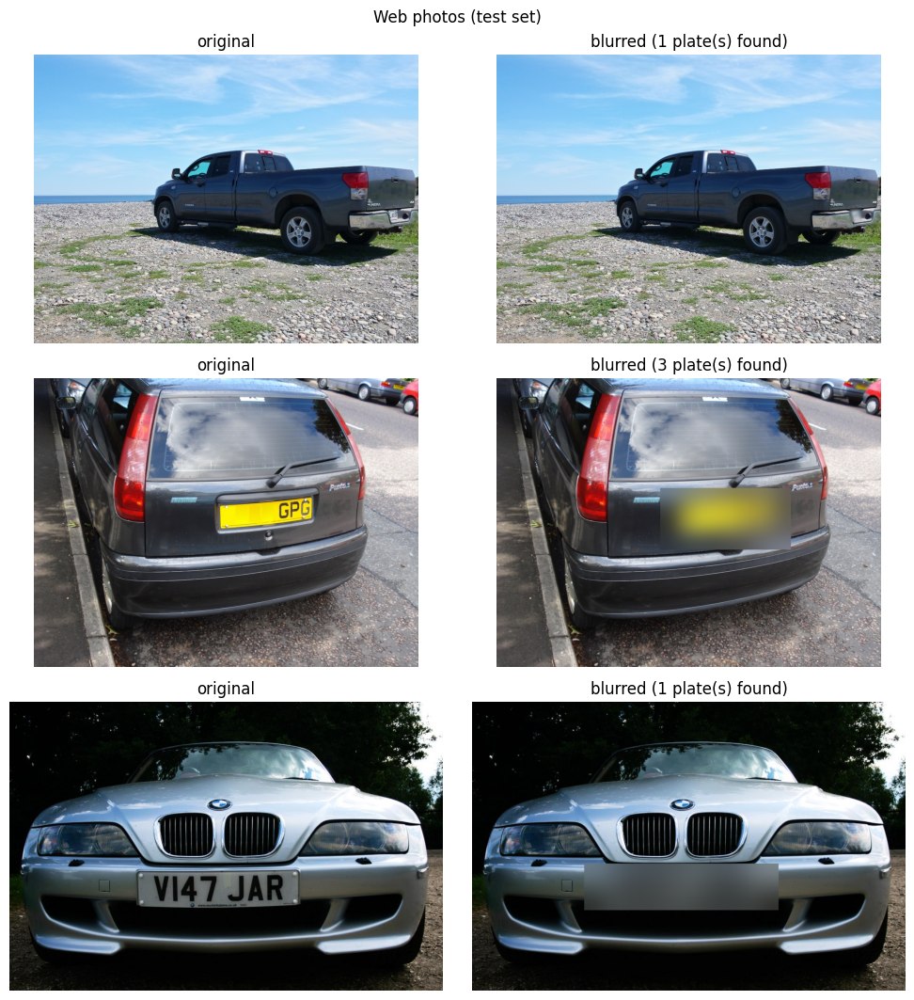

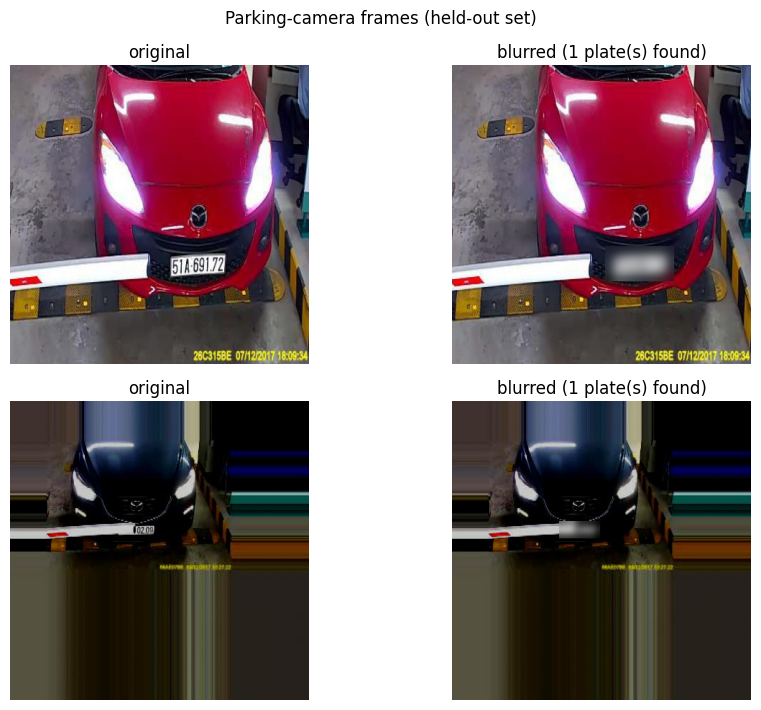

In [16]:
def padded_box(x1, y1, x2, y2, W, H, pad):
    """Enlarge a box by `pad` (fraction of its size) and clamp it to the image."""
    w, h = x2 - x1, y2 - y1
    return max(0, int(x1 - pad * w)), max(0, int(y1 - pad * h)), min(W, int(x2 + pad * w)), min(H, int(y2 + pad * h))

def blur_plates(img, boxes_xyxy, pad=PAD):
    """Gaussian-blur only the region inside each (padded) box; everything else is left untouched."""
    out = img.copy(); H, W = img.shape[:2]
    for b in boxes_xyxy:
        x1, y1, x2, y2 = padded_box(*b, W, H, pad)
        if x2 - x1 < 2 or y2 - y1 < 2: continue
        k = max(3, (max(x2 - x1, y2 - y1) // 2) | 1)               # odd kernel, scales with the plate
        out[y1:y2, x1:x2] = cv2.GaussianBlur(out[y1:y2, x1:x2], (k, k), 0)
    return out

def anonymize(path, conf=None):
    """Detect plates in one image and return (original, blurred, boxes)."""
    img = cv2.imread(path)
    boxes = model.predict(img, conf=CONF if conf is None else conf, imgsz=640, verbose=False)[0].boxes.xyxy.cpu().numpy()
    return img, blur_plates(img, boxes), boxes

def before_after(paths, title):
    fig, ax = plt.subplots(len(paths), 2, figsize=(10, 3.6 * len(paths)))
    for i, p in enumerate(paths):
        before, after, boxes = anonymize(p)
        ax[i, 0].imshow(cv2.cvtColor(before, cv2.COLOR_BGR2RGB)); ax[i, 0].set_title("original")
        ax[i, 1].imshow(cv2.cvtColor(after, cv2.COLOR_BGR2RGB)); ax[i, 1].set_title(f"blurred ({len(boxes)} plate(s) found)")
        for a in ax[i]: a.axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.show()

rng = np.random.default_rng(1)
before_after([f"{ROOT}/images/test/{f}" for f in rng.choice(sorted(os.listdir(f"{ROOT}/images/test")), 3, replace=False)],
             "Web photos (test set)")
before_after([f"{HELD}/images/test/{f}" for f in rng.choice(sorted(os.listdir(f"{HELD}/images/test")), 2, replace=False)],
             "Parking-camera frames (held-out set)")

In [17]:
# Proof that blurring stays inside the boxes: count changed pixels outside every padded box
outside_changed, plates_blurred = 0, 0
for f in sorted(os.listdir(f"{ROOT}/images/test"))[:100]:
    img, out, boxes = anonymize(f"{ROOT}/images/test/{f}")
    H, W = img.shape[:2]; mask = np.zeros((H, W), bool)
    for b in boxes:
        x1, y1, x2, y2 = padded_box(*b, W, H, PAD); mask[y1:y2, x1:x2] = True
    outside_changed += int((img != out).any(axis=2)[~mask].sum()); plates_blurred += len(boxes)
print(f"100 test images, {plates_blurred} plates blurred -> pixels changed outside the padded boxes: {outside_changed}")
assert outside_changed == 0

100 test images, 150 plates blurred -> pixels changed outside the padded boxes: 0


## 11. Blur effectiveness: can OCR still read the plates?

I run an OCR engine (EasyOCR) on every ground-truth plate region of the test set, once in the original image and once in the anonymised image produced by the full pipeline. A plate counts as *readable* if OCR returns at least four letters/digits with confidence of 0.4 or more. A plate the detector **missed** stays readable, so this measures the whole system, not only the blur. OCR is only a proxy for a human reader, and it cannot read every original plate (they are often tiny), so the figure is a lower bound on risk.

In [18]:
!pip -q install easyocr
import easyocr
reader = easyocr.Reader(["en"], gpu=torch.cuda.is_available(), verbose=False)

def readable(crop, min_chars=4, min_conf=0.4):
    if crop.shape[0] < 8 or crop.shape[1] < 8: return False
    crop = cv2.resize(crop, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC)
    return any(c >= min_conf and len(re.sub(r"[^A-Za-z0-9]", "", t)) >= min_chars for _, t, c in reader.readtext(crop))

rows = []
for f in sorted(os.listdir(f"{ROOT}/images/test")):
    before, after, _ = anonymize(f"{ROOT}/images/test/{f}")
    H, W = before.shape[:2]
    for x1, y1, x2, y2 in read_gt(ROOT, "test", f, W, H).astype(int):
        x1, y1 = max(0, x1), max(0, y1)
        rows.append(dict(before=readable(before[y1:y2, x1:x2]), after=readable(after[y1:y2, x1:x2])))
ocr = pd.DataFrame(rows)
leak_rate = (ocr.before & ocr.after).sum() / max(1, ocr.before.sum())
print(f"test plates: {len(ocr)}")
print(f"OCR-readable in the original:  {ocr.before.sum()} ({ocr.before.mean():.1%})")
print(f"OCR-readable after blurring:   {ocr.after.sum()} ({ocr.after.mean():.1%})")
print(f"leak rate (readable before AND still readable after): {leak_rate:.1%}")

test plates: 512
OCR-readable in the original:  201 (39.3%)
OCR-readable after blurring:   4 (0.8%)
leak rate (readable before AND still readable after): 2.0%


**Result.** In my run OCR could read about 39% of the original plates but only about 1% after anonymisation, so roughly 2% of the plates that were readable before remain readable: the blur defeats OCR, and almost all of the remaining leakage comes from plates the detector missed.

## 12. Speed and video

Latency is measured one image at a time (batch size 1, as for a live camera), including pre-processing, the network and non-maximum suppression, on the Colab device shown in the output (a T4 GPU when available, otherwise CPU). A second measurement adds the blur and image reading. Finally the same pipeline is run on a short video.

In [19]:
files = [f"{ROOT}/images/test/{f}" for f in sorted(os.listdir(f"{ROOT}/images/test"))[:100]]
for p in files[:10]: model.predict(p, imgsz=640, verbose=False)                       # GPU warm-up

sp = []
for p in files: sp.append(model.predict(p, conf=CONF, imgsz=640, verbose=False)[0].speed)
sp = pd.DataFrame(sp).mean()
detect_ms = float(sp.sum())

t0 = time.perf_counter()
for p in files: anonymize(p)
total_ms = (time.perf_counter() - t0) / len(files) * 1000

LATENCY = dict(device=DEVICE, detect_ms=round(detect_ms, 1), detect_fps=round(1000 / detect_ms), detect_plus_blur_ms=round(total_ms, 1), detect_plus_blur_fps=round(1000 / total_ms))
print(f"per image: preprocess {sp.preprocess:.1f} ms + inference {sp.inference:.1f} ms + postprocess {sp.postprocess:.1f} ms = {detect_ms:.1f} ms  (~{1000 / detect_ms:.0f} FPS)")
print(f"detect + read + blur end to end: {total_ms:.1f} ms per image (~{1000 / total_ms:.0f} FPS)  [{DEVICE}, batch size 1]")

per image: preprocess 2.1 ms + inference 10.0 ms + postprocess 1.8 ms = 13.9 ms  (~72 FPS)
detect + read + blur end to end: 68.7 ms per image (~15 FPS)  [Tesla T4, batch size 1]


In [20]:
def blur_video(src, dst, conf=None):
    """Blur plates frame by frame in a video file; returns (frames, throughput in FPS)."""
    cap = cv2.VideoCapture(src); fps = cap.get(cv2.CAP_PROP_FPS) or 25
    W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    out = cv2.VideoWriter(dst, cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
    n, t0 = 0, time.perf_counter()
    while True:
        ok, frame = cap.read()
        if not ok: break
        boxes = model.predict(frame, conf=CONF if conf is None else conf, imgsz=640, verbose=False)[0].boxes.xyxy.cpu().numpy()
        out.write(blur_plates(frame, boxes)); n += 1
    cap.release(); out.release()
    return n, n / (time.perf_counter() - t0)

# Demo clip: 90 held-out parking-camera frames stitched into a short video
DEMO_IN, DEMO_OUT = "/content/demo_in.mp4", "/content/demo_blurred.mp4"
vw = cv2.VideoWriter(DEMO_IN, cv2.VideoWriter_fourcc(*"mp4v"), 25, (640, 480))
for f in sorted(os.listdir(f"{HELD}/images/test"))[:90]:
    vw.write(cv2.resize(cv2.imread(f"{HELD}/images/test/{f}"), (640, 480)))
vw.release()
n_frames, video_fps = blur_video(DEMO_IN, DEMO_OUT)
print(f"processed {n_frames} frames at {video_fps:.0f} FPS (read + detect + blur + write); output: {DEMO_OUT}")

processed 90 frames at 18 FPS (read + detect + blur + write); output: /content/demo_blurred.mp4


**Reading the speed numbers (Tesla T4, from the output above).** The detector alone takes about 14 ms per image at batch size 1 (about 72 FPS), so detection comfortably meets real-time needs. The complete pipeline, which also reads the JPEG, copies the boxes to the CPU and blurs, took about 69 ms per image (about 15 FPS) on the mostly 1,000-pixel web photos, and the 90-frame 640x480 demo clip ran at about 18 FPS including video decoding and encoding. So **as written, the full pipeline is below the 25-30 FPS of a typical camera stream, and the detector is not the bottleneck.** The extra time is CPU-side work: image decoding and encoding, and the Gaussian blur, whose kernel grows with plate size. I did not profile these parts separately. Cheap fixes are to cap the kernel size or blur a down-scaled copy of each box, use hardware video decoding, and batch frames; speed should be re-measured after any change and on the real target device. The demo clip is built from still images (so the scenes jump), but a real stream goes through exactly the same function.

## 13. Results summary, insights and recommendations

In [21]:
summary = pd.DataFrame(RESULTS).T.round(3)
display(summary)
print("Operating point: CONF =", CONF, "| box padding =", PAD)
print("Latency:", LATENCY, "| video throughput:", round(video_fps), "FPS")
print(f"OCR leak rate after blurring (test): {leak_rate:.1%}")

,P,R,mAP50,mAP50_95
"val (web photos, 1,043 imgs)",0.853,0.771,0.820,0.416
"test (web photos, 386 imgs)",0.914,0.812,0.881,0.640
held-out parking camera (400 imgs),0.999,1.000,0.995,0.674


Operating point: CONF = 0.1 | box padding = 0.08
Latency: {'device': 'Tesla T4', 'detect_ms': 13.9, 'detect_fps': 72, 'detect_plus_blur_ms': 68.7, 'detect_plus_blur_fps': 15} | video throughput: 18 FPS
OCR leak rate after blurring (test): 2.0%


### What I learned

- **The core case works.** On parking-camera images the system finds essentially every plate (recall about 1.00 on unseen frames), and an OCR engine cannot read the blurred results (about 2% of OCR-readable plates leak, almost all of them detector misses).
- **Small, distant plates are the weak point.** Recall drops to about 0.49 below 20 px and about 0.82 at 20-40 px; plates under 40 px cause roughly 70% of misses. At `CONF = 0.10` the test set recall is about 0.89, so about 1 plate in 9 could still be exposed in a fully automatic setting.
- **Datasets hide their own gaps.** Val and test contained only web photos while training was 81% parking-camera, and 30 val images shared source photos with train. Without checking, I would have reported a flattering or irrelevant number.
- **Detection is fast, but the full pipeline is not yet real-time.** The detector runs at about 72 FPS on a T4, but reading, blurring and writing frames brings the end-to-end rate down to about 15-18 FPS, so the blur step needs optimising before it can serve a 25-30 FPS camera stream.
- **Label defects are privacy defects.** Images with visible but unlabeled plates would teach the detector to ignore plates, so label auditing is part of the privacy control, not a nicety.

### Recommendations

1. **Make the tool a mandatory pre-storage step** for any visual data entering cloud storage, public datasets, AI training sets or insurance workflows, because unmanaged plates are a regulatory liability under GDPR and CCPA.
2. **Run recall-first.** Keep the threshold low (0.10); the price is about 0.4 extra blurred patches per image, which is acceptable. Route images that contain only low-confidence detections (for example between 0.10 and 0.25) to **human review**, and audit a random sample of outputs, because fully automatic operation cannot promise 100%.
3. **Use stronger masking where the legal risk is high.** A Gaussian blur this strong defeats OCR, but mild blur can sometimes be partly reversed by deconvolution; for regulated releases use a large kernel or a solid fill.
4. **Close the small-plate gap.** Fine-tune at a larger input size (960-1280 px) or add tiled inference for high-resolution inputs, and collect more small, distant, night-time and rainy examples.
5. **Deploy at the edge.** Export to ONNX or TensorRT (half precision) and anonymise on or next to the camera, so raw plates never leave the site and bandwidth and storage costs fall. Before targeting 25-30 FPS per stream, optimise the CPU-side blur (section 12).
6. **Build a feedback loop.** Log low-confidence detections and reviewer corrections, relabel them, retrain on a schedule, and track recall by plate size and scene type so regressions on small plates are visible.
7. **Validate on the target cameras before go-live.** My parking-camera result comes from the same fixed cameras as the training data, so a new site needs its own acceptance test.
